In [1]:
# Download the data
!wget https://osf.io/download/h3d8x/ -O evt20240510.dat.db
!wget https://osf.io/download/qna3e/ -O gic_2021ultproc.dat.db

--2026-10-09 17:33:07--  https://osf.io/download/h3d8x/
Resolving osf.io (osf.io)... 35.190.84.173
Connecting to osf.io (osf.io)|35.190.84.173|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://files.ca-1.osf.io/v1/resources/av9ht/providers/osfstorage/66f2d55619d59c12ff3cbbe7 [following]
--2026-10-09 17:33:08--  https://files.ca-1.osf.io/v1/resources/av9ht/providers/osfstorage/66f2d55619d59c12ff3cbbe7
Resolving files.ca-1.osf.io (files.ca-1.osf.io)... 35.241.38.243
Connecting to files.ca-1.osf.io (files.ca-1.osf.io)|35.241.38.243|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://storage.googleapis.com/cos-osf-prod-files-ca-1/ccf441009e36fc9db63ea80a186ce42444ba8f9a1fb42dabbf6f697e6872f192?response-content-disposition=attachment%3B%20filename%3D%22evt20240510.dat.db%22%3B%20filename%2A%3DUTF-8%27%27evt20240510.dat.db&GoogleAccessId=files-ca-1%40cos-osf-prod.iam.gserviceaccount.com&Expires=1791567249&Signature=UiLFD

In [2]:
import numpy as np
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [3]:
!du -sh evt20240510.dat.db
!du -sh gic_2021ultproc.dat.db

1.4M	evt20240510.dat.db
67M	gic_2021ultproc.dat.db


In [4]:
import shelve

with shelve.open('evt20240510.dat', 'r') as shelf:
    print("Keys in shelf:", list(shelf.keys()))

    # Access your data
    evt20240510 = shelf['evt20240510']
    gic_est3 = shelf['gic_est3']
    gic_obs = shelf['gic_obs']

    print("evt20240510 shape:", evt20240510.shape)
    print("gic_est3 shape:", gic_est3.shape)
    print("gic_obs shape:", gic_obs.shape)

Keys in shelf: ['gic_est2', 'gic_est', 'gic_obs', 'evt20240510', 'gic_est3']
evt20240510 shape: (5760, 10)
gic_est3 shape: (5760, 4)
gic_obs shape: (5760, 4)


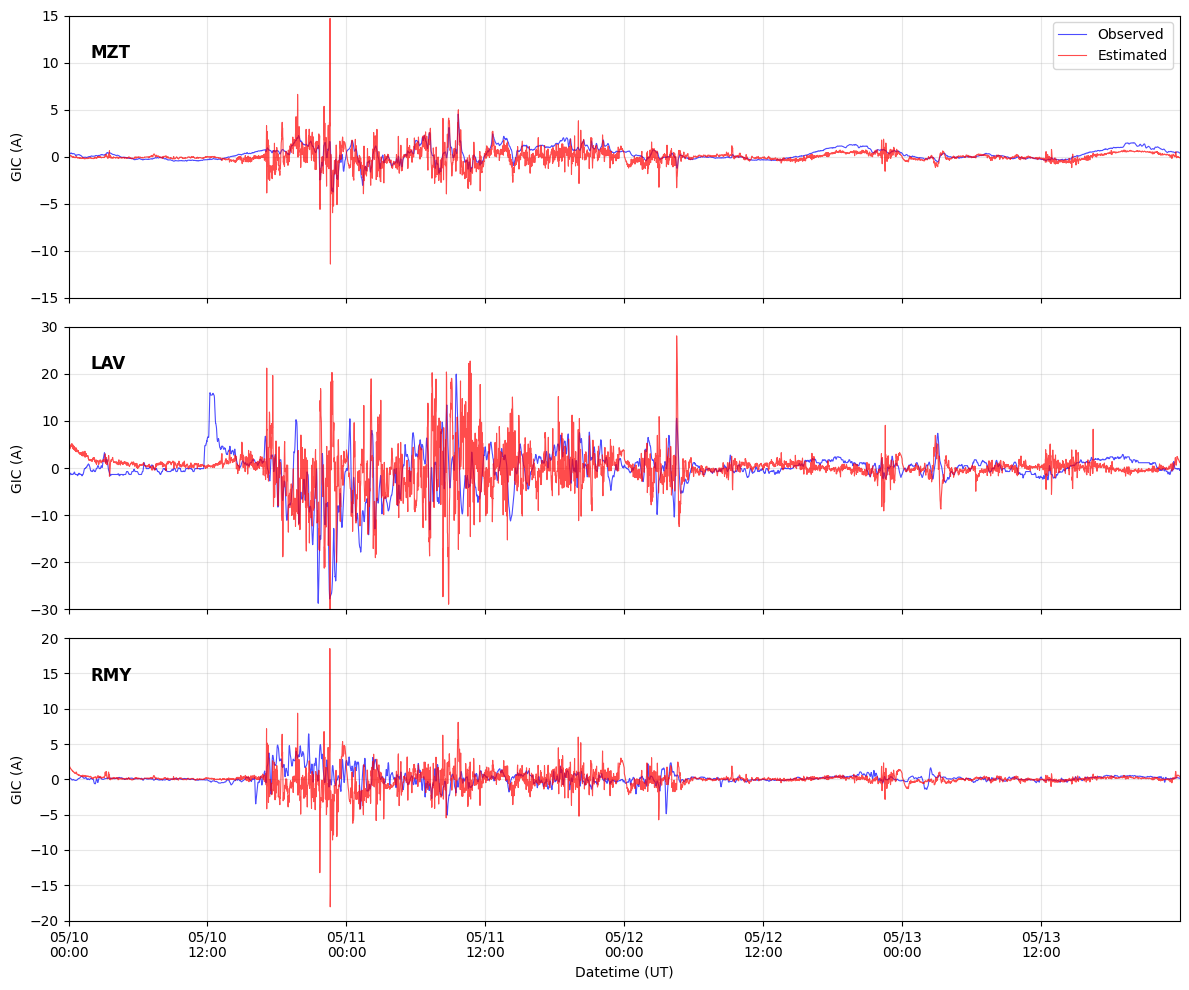

MZT: r=0.578, RMSE=0.8A
LAV: r=0.142, RMSE=5.5A
RMY: r=-0.097, RMSE=1.6A


In [5]:
with shelve.open('evt20240510.dat', 'r') as shelf:
    evt20240510 = shelf['evt20240510']
    gic_est3 = shelf['gic_est3']
    gic_obs = shelf['gic_obs']

if hasattr(evt20240510, 'index'):
    datetime_index = evt20240510.index
else:
    datetime_index = pd.date_range(start='2024-05-10', periods=len(gic_obs), freq='min')

gic_obs_df = pd.DataFrame(gic_obs, index=datetime_index, columns=['MZT', 'QRO', 'LAV', 'RMY'])
gic_est_df = pd.DataFrame(gic_est3, index=datetime_index, columns=['MZT', 'QRO', 'LAV', 'RMY'])

stations = ['MZT', 'LAV', 'RMY']
y_limits = [(-15, 15), (-30, 30), (-20, 20)]

fig, axes = plt.subplots(len(stations), 1, figsize=(12, 10), sharex=True)

for i, (ax, station, ylim) in enumerate(zip(axes, stations, y_limits)):
    ax.plot(gic_obs_df.index, gic_obs_df[station], 'b-', linewidth=0.8, alpha=0.7, label='Observed')
    ax.plot(gic_est_df.index, gic_est_df[station], 'r-', linewidth=0.8, alpha=0.7, label='Estimated')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(ylim)
    ax.set_ylabel('GIC (A)')
    ax.text(0.02, 0.85, station, transform=ax.transAxes, fontsize=12, fontweight='bold')
    if i == 0:
        ax.legend(loc='upper right')

axes[-1].set_xlabel('Datetime (UT)')
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=12))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d\n%H:%M'))

for ax in axes:
    ax.set_xlim(gic_obs_df.index[0], gic_obs_df.index[-1])

plt.tight_layout()
plt.show()

for station in stations:
    obs_data = gic_obs_df[station]
    est_data = gic_est_df[station]
    correlation = np.corrcoef(obs_data, est_data)[0, 1]
    rmse = np.sqrt(np.mean((obs_data - est_data)**2))
    print(f"{station}: r={correlation:.3f}, RMSE={rmse:.1f}A")

In [6]:
# Combine the observed and estimated GIC data into a single DataFrame for convenient export
combined_df = gic_obs_df.join(gic_est_df, lsuffix='_observed', rsuffix='_estimated')

# Name the index (time) column
combined_df.index.name = 'Date'

# Save to CSV with the named index
combined_df.to_csv('evt20240510.csv')
print("Saved combined data to 'evt20240510.csv' with 'Datetime (UT)' as the time column name.")

Saved combined data to 'evt20240510.csv' with 'Datetime (UT)' as the time column name.


['gic_corr', 'T1', 'T2']
['gic_corr', 'T1', 'T2']
['QRP', 'LAV']
['LAVx', 'LAVy', 'QRPx', 'QRPy']
['LAVX', 'LAVY', 'QRPX', 'QRPY']
['DOY', 'ASY-D', 'ASY-H', 'SYM-D', 'SYM-H']
['TUCX', 'TUCY', 'TUCZ', 'D']


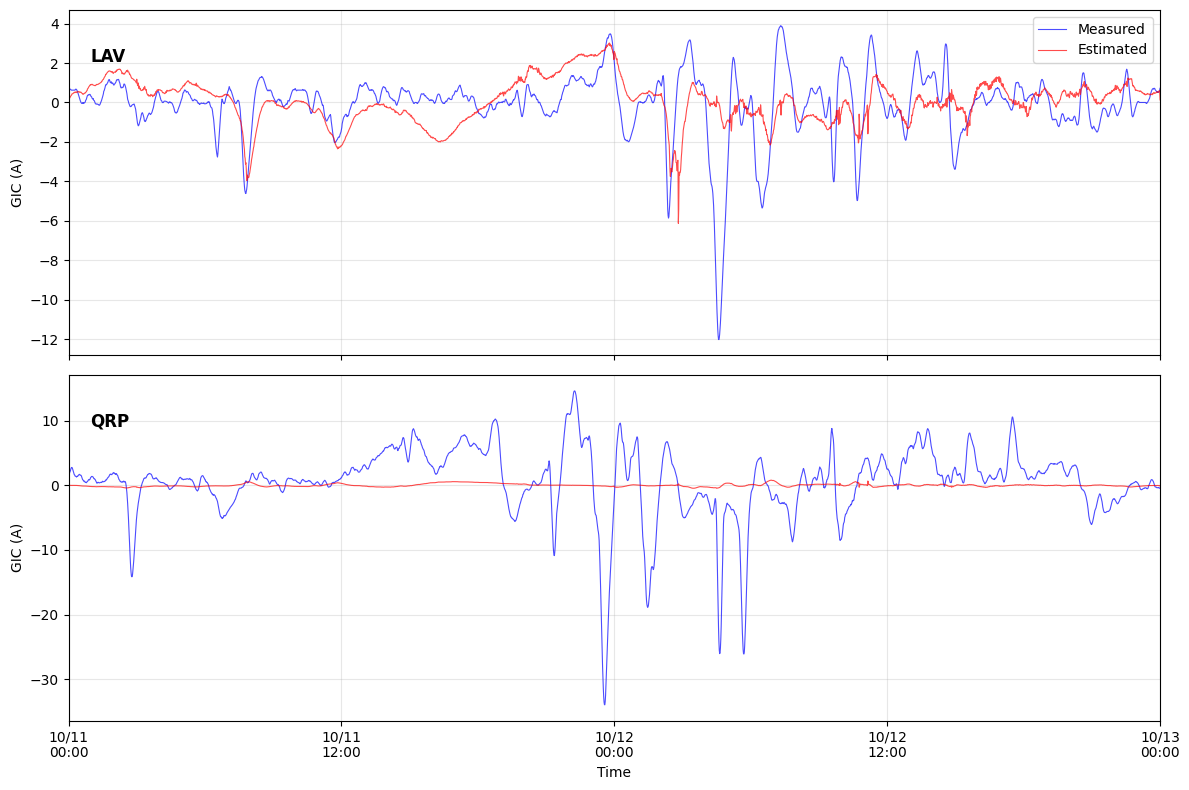

In [7]:
import shelve
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

with shelve.open('gic_2021ultproc.dat', 'r') as shelf:
    qrpp = shelf['qrpp']
    lavp = shelf['lavp']
    gic_est = shelf['gic_est']
    efield = shelf['efield']
    bfield = shelf['bfield']
    symH = shelf['symH']
    tuc = shelf['tuc']

# print all keys
print(list(qrpp.keys()))
print(list(lavp.keys()))
print(list(gic_est.keys()))
print(list(efield.keys()))
print(list(bfield.keys()))
print(list(symH.keys()))
print(list(tuc.keys()))


lave = lavp.loc['2021-10-11':'2021-10-13 00:00:00', :]
qrpe = qrpp.loc['2021-07-28':'2021-11-30 12:00:00', :]
gic_est_subset = gic_est.loc['2021-10-11':'2021-10-13 00:00:00', :]

LAV_GIC_meas = lave.loc[:, 'gic_corr']
LAV_GIC_est = gic_est_subset.loc[:, 'LAV']

# QRP dataset matches the time range of LAV_GIC_meas for a clean comparison
QRP_GIC_meas = qrpe.loc['2021-10-11':'2021-10-13 00:00:00', 'gic_corr']
QRP_GIC_est = gic_est_subset.loc[:, 'QRP']

# Create subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# LAV subplot
axes[0].plot(LAV_GIC_meas.index, LAV_GIC_meas, 'b-', linewidth=0.8, alpha=0.7, label='Measured')
axes[0].plot(LAV_GIC_est.index, LAV_GIC_est, 'r-', linewidth=0.8, alpha=0.7, label='Estimated')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylabel('GIC (A)')
axes[0].text(0.02, 0.85, 'LAV', transform=axes[0].transAxes, fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right')

# QRP subplot
axes[1].plot(QRP_GIC_meas.index, QRP_GIC_meas, 'b-', linewidth=0.8, alpha=0.7, label='Measured')
axes[1].plot(QRP_GIC_est.index, QRP_GIC_est, 'r-', linewidth=0.8, alpha=0.7, label='Estimated')
axes[1].grid(True, alpha=0.3)
axes[1].set_ylabel('GIC (A)')
axes[1].text(0.02, 0.85, 'QRP', transform=axes[1].transAxes, fontsize=12, fontweight='bold')

axes[-1].set_xlabel('Time')
axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=12))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d\n%H:%M'))

for ax in axes:
    ax.set_xlim(LAV_GIC_meas.index[0], LAV_GIC_meas.index[-1])

plt.tight_layout()
plt.show()

In [8]:
# Extract individual columns
lav_measured = lavp[['gic_corr']].rename(columns={'gic_corr': 'LAV_observed'})
qrp_measured = qrpp[['gic_corr']].rename(columns={'gic_corr': 'QRP_observed'})
lav_estimated = gic_est[['LAV']].rename(columns={'LAV': 'LAV_estimated'})
qrp_estimated = gic_est[['QRP']].rename(columns={'QRP': 'QRP_estimated'})

# Combine into a single DataFrame
combined_2021_df = lav_measured.join([qrp_measured, lav_estimated, qrp_estimated], how='outer')

# Name the index
combined_2021_df.index.name = 'Date'

# Save to CSV
combined_2021_df.to_csv('gic_2021ultproc.csv')
print("Saved combined 2021 data to 'gic_2021ultproc.csv'")
display(combined_2021_df.head())


Saved combined 2021 data to 'gic_2021ultproc.csv'


,LAV_observed,QRP_observed,LAV_estimated,QRP_estimated
Date,,,,
2021-01-01 00:00:00,NaN,0.143454,NaN,NaN
2021-01-01 00:01:00,NaN,0.082935,NaN,NaN
2021-01-01 00:02:00,NaN,0.043449,NaN,NaN
2021-01-01 00:03:00,NaN,0.022361,NaN,NaN
2021-01-01 00:04:00,NaN,0.017034,NaN,NaN


In [9]:
# Extract TUC magnetic field columns and rename them
tuc_export = tuc[['TUCX', 'TUCY', 'TUCZ']].rename(columns={
    'TUCX': 'Bx',
    'TUCY': 'By',
    'TUCZ': 'Bz'
})

# Set the index name to 'date'
tuc_export.index.name = 'date'

# Save to CSV
tuc_export.to_csv('tuc_magnetic_field.csv')
print("Saved TUC data to 'tuc_magnetic_field.csv'")
display(tuc_export.head())

Saved TUC data to 'tuc_magnetic_field.csv'


,Bx,By,Bz
date,,,
2021-07-28 00:00:00,NaN,NaN,NaN
2021-07-28 00:01:00,NaN,NaN,NaN
2021-07-28 00:02:00,NaN,NaN,NaN
2021-07-28 00:03:00,NaN,NaN,NaN
2021-07-28 00:04:00,NaN,NaN,NaN
